In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,balanced_accuracy_score, make_scorer, mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from scipy.stats import t
from sklearn.pipeline import make_pipeline

---
# **Ερώτημα 1**

In [2]:
df = pd.read_csv("sleep.csv")

display(df.head())
print(df.info())

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

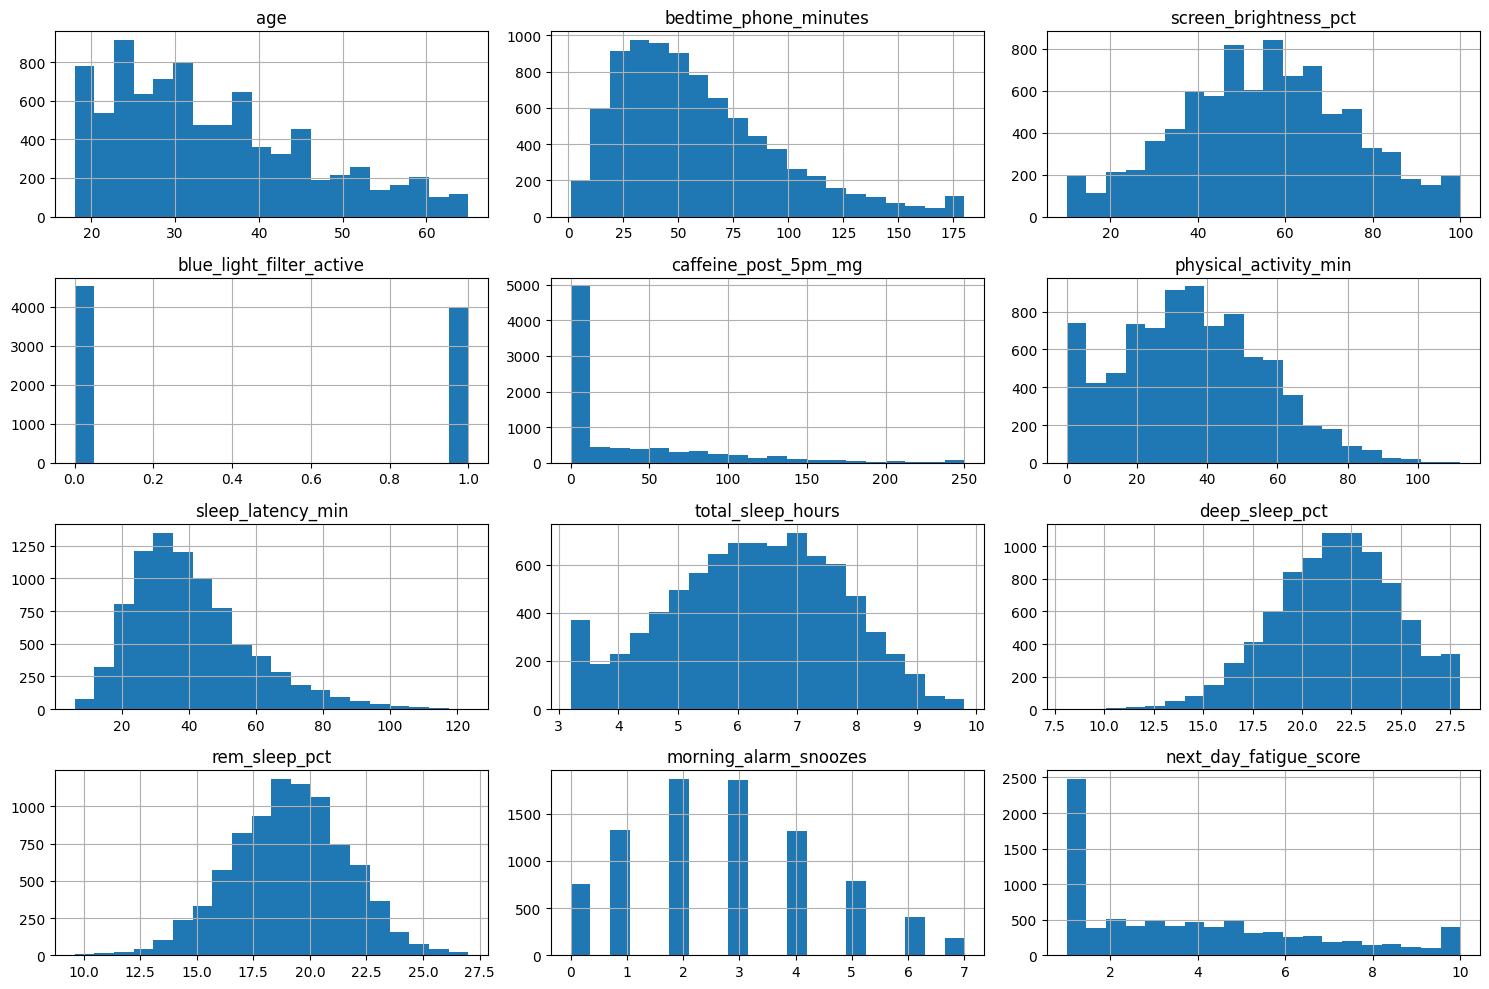

In [3]:
numeric = df.select_dtypes(include=["number"]).columns

df[numeric].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

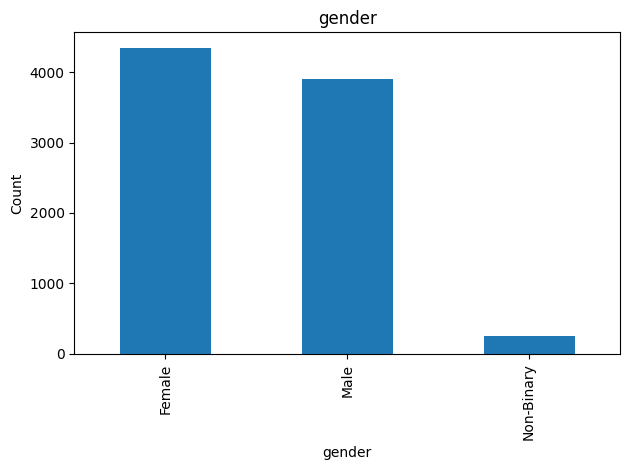

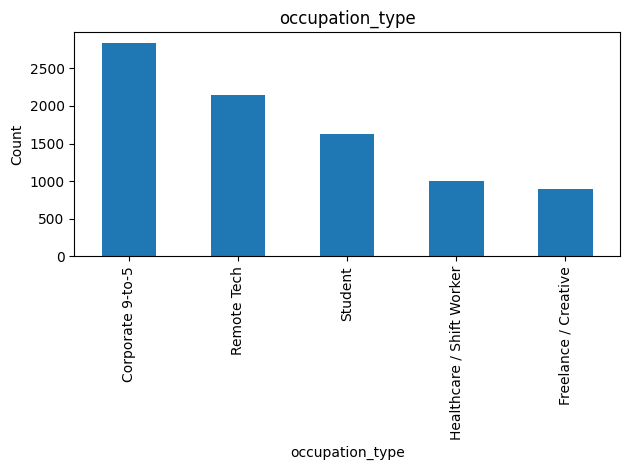

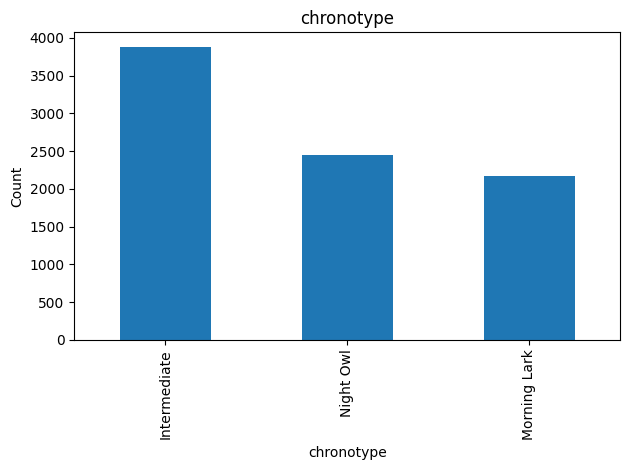

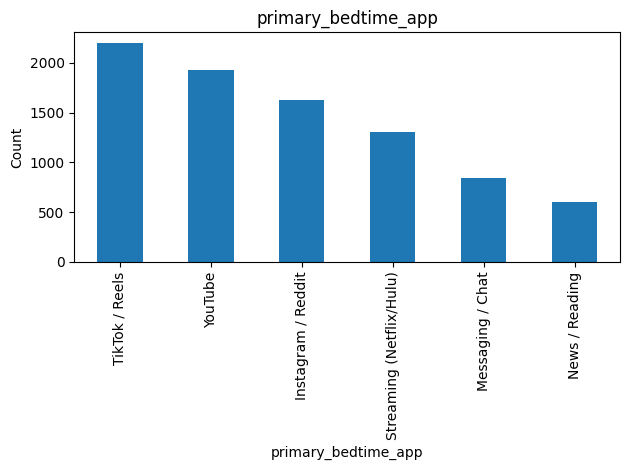

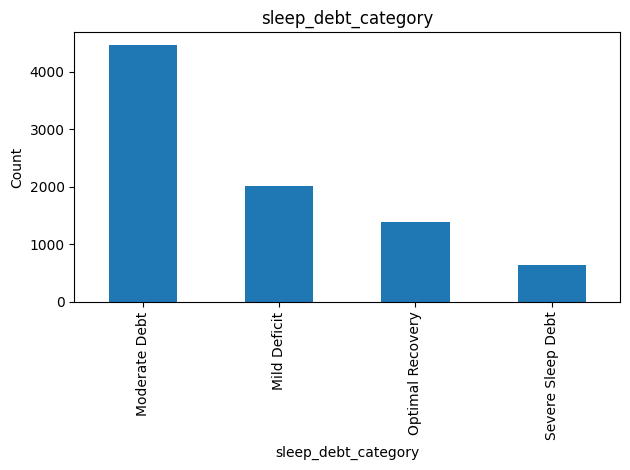

In [4]:
df = df.drop(columns=["user_id"], errors="ignore")
df = df.dropna()

categorical = df.select_dtypes(include=["object"]).columns.tolist()

for col in categorical:
    df[col].value_counts().plot(kind="bar", title=col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()





sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64
sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64


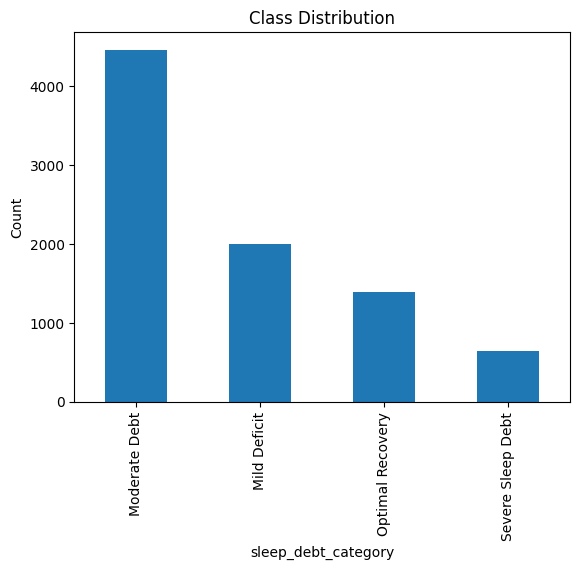

In [5]:
target = "sleep_debt_category"

print(df[target].value_counts())
print(df[target].value_counts(normalize=True) * 100)

df[target].value_counts().plot(kind="bar")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.show()

Από την κατανομή της μεταβλητής sleep_debt_category παρατηρούμε ότι οι κλάσεις δεν είναι ισορροπημένες. Η κατηγορία Moderate Debt εμφανίζεται πολύ συχνότερα, ενώ η Severe Sleep Debt έχει τα λιγότερα δείγματα. Επομένως υπάρχει ανισορροπία κλάσεων, η οποία μπορεί να επηρεάσει την απόδοση του μοντέλου.

---
# **Ερώτημα 2**

In [6]:
df = df.drop(columns=["next_day_fatigue_score"])

---
# **Ερώτημα 3**

In [7]:
df = pd.get_dummies(df,columns=["gender", "occupation_type", "chronotype", "primary_bedtime_app"],dtype=int)

In [8]:
print(df.shape)
display(df.head())

(8500, 29)


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0


---
# **Ερώτημα 4**

In [9]:
x = df.drop(columns=["sleep_debt_category"]).to_numpy()
y = df["sleep_debt_category"].to_numpy()

x_train, x_temp, y_train, y_temp = train_test_split(x, y,
    test_size=0.30,
    random_state=0,
    stratify=y
)

x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp,
    test_size=1/3,
    random_state=0,
    stratify=y_temp
)

x_train.shape, x_val.shape, x_test.shape

((5950, 28), (1700, 28), (850, 28))

---
# **Ερώτημα 5**

In [10]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

In [11]:
k_values = [3, 5, 15, 50, len(x_train)]
weights = ["uniform", "distance"]

results = []

for k in k_values:
    for w in weights:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w)
        knn.fit(x_train, y_train)

        for dataset, X, y in [("Train", x_train, y_train),("Validation", x_val, y_val)]:
            y_pred = knn.predict(X)
            results.append({
                "k": k,
                "Weights": w,
                "Dataset": dataset,
                "Accuracy": accuracy_score(y, y_pred),
                "Precision": precision_score(y, y_pred, average="weighted", zero_division=0),
                "Recall": recall_score(y, y_pred, average="weighted", zero_division=0),
                "F1": f1_score(y, y_pred, average="weighted", zero_division=0),
                "Balanced Acc": balanced_accuracy_score(y, y_pred)
            })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,k,Weights,Dataset,Accuracy,Precision,Recall,F1,Balanced Acc
0,3,uniform,Train,0.8484,0.8539,0.8484,0.8484,0.7923
1,3,uniform,Validation,0.6971,0.7087,0.6971,0.6984,0.6188
2,3,distance,Train,1.0000,1.0000,1.0000,1.0000,1.0000
3,3,distance,Validation,0.6976,0.6998,0.6976,0.6958,0.6175
4,5,uniform,Train,0.8091,0.8167,0.8091,0.8077,0.7331
5,5,uniform,Validation,0.7153,0.7293,0.7153,0.7143,0.6206
6,5,distance,Train,1.0000,1.0000,1.0000,1.0000,1.0000
7,5,distance,Validation,0.7106,0.7155,0.7106,0.7076,0.6174
8,15,uniform,Train,0.7644,0.7745,0.7644,0.7579,0.6518
9,15,uniform,Validation,0.7206,0.7323,0.7206,0.7113,0.5916


---
# **Ερώτημα 6**

In [12]:
val_results = results_df[results_df["Dataset"] == "Validation"]
best = val_results.loc[val_results["F1"].idxmax()]
print("Best combination:")
print(best)

Best combination:
k                       50
Weights           distance
Dataset         Validation
Accuracy          0.744118
Precision         0.752438
Recall            0.744118
F1                0.726634
Balanced Acc      0.593788
Name: 15, dtype: object


In [13]:
x = df.drop(columns=["sleep_debt_category"]).to_numpy()
y = df["sleep_debt_category"].to_numpy()

In [14]:
seed = 0

x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    x, y, test_size=0.3, random_state=seed, stratify=y
)

x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw, y_temp, test_size=1/3,
    random_state=seed,
    stratify=y_temp
)

In [15]:
x_train_val = np.concatenate([x_train_raw, x_val_raw])
y_train_val = np.concatenate([y_train, y_val])

scaler = StandardScaler()

x_train_val = scaler.fit_transform(x_train_val)
x_test_scaled = scaler.transform(x_test_raw)

In [16]:
best_k = int(best["k"])
best_weights = best["Weights"]

knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weights
)

knn.fit(x_train_val, y_train_val)

y_test_pred = knn.predict(x_test_scaled)

In [17]:
test_results = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, average="weighted", zero_division=0),
    "F1": f1_score(y_test, y_test_pred, average="weighted", zero_division=0),
    "Balanced Acc": balanced_accuracy_score(y_test, y_test_pred)
}

print(pd.Series(test_results).round(4))

Accuracy        0.7376
Precision       0.7465
Recall          0.7376
F1              0.7248
Balanced Acc    0.6030
dtype: float64


In [18]:
comparison = results_df[
    (results_df["k"] == best_k) &
    (results_df["Weights"] == best_weights)
].copy()

comparison = comparison.set_index("Dataset")

comparison.loc["Test", list(test_results.keys())] = list(test_results.values())

print(comparison.round(4))

               k   Weights  Accuracy  Precision  Recall      F1  Balanced Acc
Dataset                                                                      
Train       50.0  distance    1.0000     1.0000  1.0000  1.0000        1.0000
Validation  50.0  distance    0.7441     0.7524  0.7441  0.7266        0.5938
Test         NaN       NaN    0.7376     0.7465  0.7376  0.7248        0.6030


Το μοντέλο παρουσιάζει overfitting, καθώς πετυχαίνει 100% στο Train, ενώ στο Validation και στο Test το Accuracy μειώνεται περίπου στο 74%.
Οι παρόμοιες επιδόσεις σε Validation και Test δείχνουν σταθερή απόδοση σε νέα δεδομένα. Ωστόσο το χαμηλό Balanced Accuracy ~60% δείχνει ότι το μοντέλο δυσκολεύεται στην αναγνώριση όλων των κλάσεων.

---
# **Ερώτημα 7**

In [19]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.1,
    random_state=0,
    stratify=y
)

In [20]:
k_values = [3, 5, 15, 50, 4 * len(x_train) // 5]
weights = ["uniform", "distance"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, average="weighted", zero_division=0),
    "Recall": make_scorer(recall_score, average="weighted", zero_division=0),
    "F1": make_scorer(f1_score, average="weighted", zero_division=0),
    "Balanced Acc": "balanced_accuracy"
}

results = []

for k in k_values:
    for w in weights:
        model = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k, weights=w))
        scores = cross_validate(model, x_train, y_train,cv=cv,scoring=scoring)

        results.append({
            "k": k,
            "Weights": w,
            **{metric: scores[f"test_{metric}"].mean() for metric in scoring}
        })

results_df = pd.DataFrame(results)
print(results_df.round(4))

      k   Weights  Accuracy  Precision  Recall      F1  Balanced Acc
0     3   uniform    0.7037     0.7135  0.7037  0.7034        0.6162
1     3  distance    0.7020     0.7036  0.7020  0.6991        0.6142
2     5   uniform    0.7082     0.7189  0.7082  0.7059        0.6107
3     5  distance    0.7056     0.7078  0.7056  0.7009        0.6089
4    15   uniform    0.7144     0.7263  0.7144  0.7059        0.5898
5    15  distance    0.7190     0.7259  0.7190  0.7090        0.5962
6    50   uniform    0.7307     0.7411  0.7307  0.7126        0.5749
7    50  distance    0.7308     0.7391  0.7308  0.7132        0.5794
8  6120   uniform    0.5250     0.2756  0.5250  0.3614        0.2500
9  6120  distance    0.5250     0.2756  0.5250  0.3614        0.2500


In [21]:
best = results_df.loc[results_df["F1"].idxmax()]

best_k = int(best["k"])
best_weights = best["Weights"]

print("Best combination:")
print(best)

Best combination:
k                     50
Weights         distance
Accuracy         0.73085
Precision        0.73907
Recall           0.73085
F1              0.713211
Balanced Acc    0.579434
Name: 7, dtype: object


In [22]:
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k, weights=best_weights)
)

scores = cross_validate(
    model, x_train, y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    values = scores[f"test_{metric}"]

    mean = values.mean()
    margin = t.ppf(0.975, df=4) * values.std(ddof=1) / np.sqrt(5)

    print(f"{metric}: {mean:.4f} [{mean-margin:.4f}, {mean+margin:.4f}]")

Accuracy: 0.7308 [0.7216, 0.7401]
Precision: 0.7391 [0.7286, 0.7496]
Recall: 0.7308 [0.7216, 0.7401]
F1: 0.7132 [0.7023, 0.7241]
Balanced Acc: 0.5794 [0.5649, 0.5940]


In [23]:
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, y_pred, average="weighted", zero_division=0))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

Accuracy: 0.7294117647058823
Precision: 0.7449091102293806
Recall: 0.7294117647058823
F1: 0.7144461907618243
Balanced Accuracy: 0.5766411079484118


---
# **Ερώτημα 8**

In [24]:
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 15, 50, 4080],
    "kneighborsclassifier__weights": ["uniform", "distance"]
}

grid = GridSearchCV(
    model,
    param_grid,
    cv=inner_cv,
    scoring="f1_weighted"
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision_weighted",
    "Recall": "recall_weighted",
    "F1": "f1_weighted",
    "Balanced Acc": "balanced_accuracy"
}

scores = cross_validate(
    grid, x_train, y_train,
    cv=outer_cv,
    scoring=scoring,
    return_estimator=True
)

In [25]:
results = pd.DataFrame({
    metric: scores[f"test_{metric}"]
    for metric in scoring
})

results.index = ["Fold 1", "Fold 2", "Fold 3"]

print(results.round(4))

        Accuracy  Precision  Recall      F1  Balanced Acc
Fold 1    0.7086     0.7182  0.7086  0.6990        0.5839
Fold 2    0.7337     0.7424  0.7337  0.7171        0.5816
Fold 3    0.7122     0.7120  0.7122  0.6984        0.5851


In [26]:
print("\nMean Scores:")
print(results.mean().round(4))


Mean Scores:
Accuracy        0.7182
Precision       0.7242
Recall          0.7182
F1              0.7048
Balanced Acc    0.5835
dtype: float64


In [27]:
for i, estimator in enumerate(scores["estimator"], 1):
    print(f"Fold {i}: {estimator.best_params_}")

Fold 1: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'}
Fold 2: {'kneighborsclassifier__n_neighbors': 50, 'kneighborsclassifier__weights': 'distance'}
Fold 3: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'}


---
# **Μέρος 2**

In [28]:
df = pd.read_csv("sleep.csv")

df = df.drop(columns=["user_id","sleep_debt_category"])

df = pd.get_dummies(df,columns=["gender", "occupation_type", "chronotype", "primary_bedtime_app"],dtype=int)

x = df.drop(columns=["next_day_fatigue_score"]).to_numpy()
y = df["next_day_fatigue_score"].to_numpy()

In [29]:
seed = 0

x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.3, random_state=seed
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=1/3, random_state=seed
)

In [30]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)

k_values = [3, 5, 15, 50, len(x_train)]
weights = ["uniform", "distance"]

results = []

for k in k_values:
    for w in weights:
        knn = KNeighborsRegressor(n_neighbors=k, weights=w)
        knn.fit(x_train_scaled, y_train)

        for dataset, X, y_true in [
            ("Train", x_train_scaled, y_train),
            ("Validation", x_val_scaled, y_val)
        ]:
            y_pred = knn.predict(X)

            results.append({
                "k": k,
                "Weights": w,
                "Dataset": dataset,
                "MAE": mean_absolute_error(y_true, y_pred),
                "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
                "R2": r2_score(y_true, y_pred)
            })

results_df = pd.DataFrame(results)
print(results_df.round(4))

       k   Weights     Dataset     MAE    RMSE      R2
0      3   uniform       Train  0.6336  0.8716  0.8939
1      3   uniform  Validation  0.8854  1.2031  0.7975
2      3  distance       Train  0.0000  0.0000  1.0000
3      3  distance  Validation  0.8770  1.1944  0.8004
4      5   uniform       Train  0.7163  0.9583  0.8717
5      5   uniform  Validation  0.8530  1.1463  0.8162
6      5  distance       Train  0.0000  0.0000  1.0000
7      5  distance  Validation  0.8421  1.1343  0.8200
8     15   uniform       Train  0.8457  1.0808  0.8368
9     15   uniform  Validation  0.8936  1.1435  0.8171
10    15  distance       Train  0.0000  0.0000  1.0000
11    15  distance  Validation  0.8771  1.1244  0.8231
12    50   uniform       Train  0.9278  1.1580  0.8127
13    50   uniform  Validation  0.9400  1.1792  0.8055
14    50  distance       Train  0.0000  0.0000  1.0000
15    50  distance  Validation  0.9269  1.1641  0.8104
16  5950   uniform       Train  2.2407  2.6754 -0.0000
17  5950  

In [31]:
val_results = results_df[results_df["Dataset"] == "Validation"]

best = val_results.loc[val_results["RMSE"].idxmin()]

best_k = int(best["k"])
best_weights = best["Weights"]

print(best)

k                  15
Weights      distance
Dataset    Validation
MAE          0.877082
RMSE         1.124404
R2           0.823118
Name: 11, dtype: object


In [32]:
x_train_val = np.concatenate([x_train, x_val])
y_train_val = np.concatenate([y_train, y_val])

scaler = StandardScaler()

x_train_val = scaler.fit_transform(x_train_val)
x_test_scaled = scaler.transform(x_test)

knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights=best_weights
)

knn.fit(x_train_val, y_train_val)
y_test_pred = knn.predict(x_test_scaled)

In [33]:
test_results = {
    "MAE": mean_absolute_error(y_test, y_test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "R2": r2_score(y_test, y_test_pred)
}

comparison = results_df[
    (results_df["k"] == best_k) &
    (results_df["Weights"] == best_weights)
].copy()

comparison = comparison.set_index("Dataset")
comparison.loc["Test", list(test_results)] = list(test_results.values())

print(comparison.round(4))

               k   Weights     MAE    RMSE      R2
Dataset                                           
Train       15.0  distance  0.0000  0.0000  1.0000
Validation  15.0  distance  0.8771  1.1244  0.8231
Test         NaN       NaN  0.8582  1.1164  0.8379


In [34]:

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.1, random_state=0
)

cv = KFold(n_splits=5, shuffle=True, random_state=0)

k_values = [3, 5, 15, 50, 4 * len(x_train) // 5]
weights = ["uniform", "distance"]

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

results = []

for k in k_values:
    for w in weights:
        model = make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=k, weights=w))
        scores = cross_validate(model, x_train, y_train,cv=cv, scoring=scoring)

        results.append({
            "k": k,
            "Weights": w,
            "MAE": -scores["test_MAE"].mean(),
            "RMSE": -scores["test_RMSE"].mean(),
            "R2": scores["test_R2"].mean()
        })

cv_results = pd.DataFrame(results)
print(cv_results.round(4))

      k   Weights     MAE    RMSE      R2
0     3   uniform  0.8991  1.2154  0.7943
1     3  distance  0.8899  1.2045  0.7980
2     5   uniform  0.8768  1.1654  0.8110
3     5  distance  0.8652  1.1518  0.8153
4    15   uniform  0.8975  1.1490  0.8162
5    15  distance  0.8822  1.1316  0.8218
6    50   uniform  0.9427  1.1787  0.8066
7    50  distance  0.9292  1.1640  0.8114
8  6120   uniform  2.2468  2.6816 -0.0003
9  6120  distance  2.1171  2.5378  0.1041


In [35]:
best = cv_results.loc[cv_results["RMSE"].idxmin()]

best_k = int(best["k"])
best_weights = best["Weights"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=best_k, weights=best_weights)
)

scores = cross_validate(
    model, x_train, y_train,
    cv=cv, scoring=scoring
)

for metric in scoring:
    values = scores[f"test_{metric}"]

    if metric != "R2":
        values = -values

    mean = values.mean()
    margin = t.ppf(0.975, 4) * values.std(ddof=1) / np.sqrt(5)

    print(f"{metric}: {mean:.4f} [{mean-margin:.4f}, {mean+margin:.4f}]")

MAE: 0.8822 [0.8526, 0.9118]
RMSE: 1.1316 [1.0985, 1.1647]
R2: 0.8218 [0.8106, 0.8329]


In [36]:
outer_cv = KFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=0)

model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor()
)

param_grid = {
    "kneighborsregressor__n_neighbors": [3, 5, 15, 50, 4080],
    "kneighborsregressor__weights": ["uniform", "distance"]
}

grid = GridSearchCV(
    model,
    param_grid,
    cv=inner_cv,
    scoring="neg_root_mean_squared_error"
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

scores = cross_validate(
    grid, x_train, y_train,
    cv=outer_cv,
    scoring=scoring,
    return_estimator=True
)

In [37]:
nested_results = pd.DataFrame({
    "MAE": -scores["test_MAE"],
    "RMSE": -scores["test_RMSE"],
    "R2": scores["test_R2"]
})

print(nested_results.round(4))

print("\nMean Scores:")
print(nested_results.mean().round(4))

for i, estimator in enumerate(scores["estimator"], 1):
    print(f"Fold {i}: {estimator.best_params_}")

      MAE    RMSE      R2
0  0.8866  1.1319  0.8240
1  0.8935  1.1540  0.8143
2  0.9023  1.1491  0.8145

Mean Scores:
MAE     0.8941
RMSE    1.1450
R2      0.8176
dtype: float64
Fold 1: {'kneighborsregressor__n_neighbors': 15, 'kneighborsregressor__weights': 'distance'}
Fold 2: {'kneighborsregressor__n_neighbors': 15, 'kneighborsregressor__weights': 'distance'}
Fold 3: {'kneighborsregressor__n_neighbors': 15, 'kneighborsregressor__weights': 'distance'}
